# Figure 3 — Chord plot: fibroblast signalling network by reaction family (post-revision)

Cleaned version of `chord_plots_2.ipynb`.

**Produces:** a `pycirclize` chord diagram showing the 96-node network grouped into five reaction families (ECM turnover, Mechanosensitive contractile program, Inflammatory stress & immune remodeling, Mechanotransduction & cytoskeleton remodeling, TGFB-MAPK-MMPs activation). Outer arcs indicate family membership of each node's dominant participation; chords show regulatory interactions coloured by family.

**Input files required in the same folder:**
- `interactions_with_families.csv` — one row per reaction with its assigned family index (post-correction version).
- `node_families_chord.csv` — ordered list of nodes with their default family assignment.

**Saves:** `chord_reaction_with_dominance_arcs.png` in the current working directory.

**Requires:** `pip install pycirclize` (not in the default blackbox_env; install locally).

/Users/lauranunez/Library/Python/3.9/lib/python/site-packages/pycirclize/sector.py:159: UserWarning: r_lim=(108, 115) is unexpected plot range (0 <= r <= 100).
  warnings.warn(f"{r_lim=} is unexpected plot range (0 <= r <= 100).")


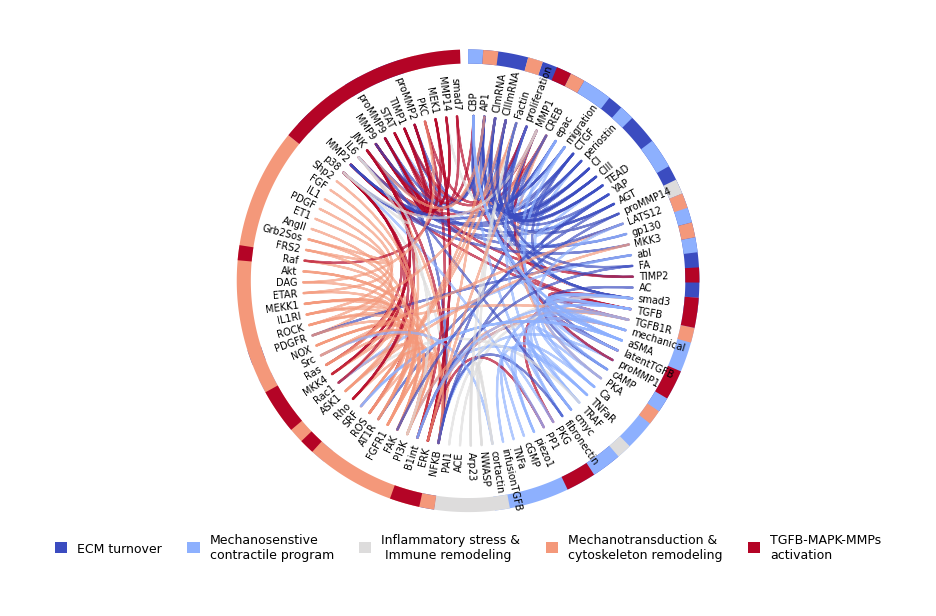

In [1]:
import pandas as pd
import numpy as np
from pycirclize import Circos
from matplotlib import cm
from collections import defaultdict
import re

# ============================================================
# FILES
# ============================================================
PATH_RULES = "interactions_with_families.csv"
PATH_NODEF = "node_families_chord.csv"

df_rxn = pd.read_csv(PATH_RULES)
df_nodes = pd.read_csv(PATH_NODEF)

df_rxn = df_rxn[df_rxn["Family"] != -1].copy()

df_nodes = df_nodes.rename(columns={"Node": "node", "Family": "node_family"})
df_nodes["node_family"] = df_nodes["node_family"].fillna(-1).astype(int)

# ============================================================
# REACTION FAMILY COLORS
# ============================================================
coolwarm_colors = cm.coolwarm([0.0, 0.25, 0.5, 0.75, 1.0])
reaction_family_colors = {
    i: cm.colors.to_hex(coolwarm_colors[i]) for i in range(5)
}

# family_name_map = {
#     0: "ECM remodeling",
#     1: "Contractility",
#     2: "Inflammation",
#     3: "Mechanotransduction",
#     4: "TGFB-axis",
# }

family_name_map = {
    0: " ",
    1: " ",
    2: " ",
    3: " ",
    4: " ",
}

# ============================================================
# PARSE REACTIONS (ROBUST)
# ============================================================
edges = []
node_reaction_count = defaultdict(lambda: defaultdict(int))

def normalize_token(x):
    x = x.strip()
    if x.startswith("!"):
        x = x[1:]
    if x.startswith("~"):
        x = x[1:]
    return x

def split_sources(src_block):
    parts = re.split(r"[&,+]", src_block)
    return [normalize_token(p) for p in parts if normalize_token(p)]

for _, row in df_rxn.iterrows():

    rfam = int(row["Family"])
    rule = str(row["Rule"]).strip().replace(" ", "")

    if "=>" in rule:
        src_block, tgt = rule.split("=>", 1)
        tgt = normalize_token(tgt)

        for src in split_sources(src_block):
            edges.append((src, tgt, rfam))
            node_reaction_count[src][rfam] += 1
            node_reaction_count[tgt][rfam] += 1

    elif "-|" in rule:
        src_block, tgt = rule.split("-|", 1)
        tgt = normalize_token(tgt)

        for src in split_sources(src_block):
            edges.append((src, tgt, rfam))
            node_reaction_count[src][rfam] += 1
            node_reaction_count[tgt][rfam] += 1

# ============================================================
# BUILD PARTICIPATION MATRIX
# ============================================================
nodes = df_nodes["node"].tolist()
node_index = {n: i for i, n in enumerate(nodes)}

X = np.zeros((len(nodes), 5))

for node, fam_counts in node_reaction_count.items():
    if node not in node_index:
        continue
    i = node_index[node]
    for rfam, count in fam_counts.items():
        if rfam in reaction_family_colors:
            X[i, rfam] = count

# Normalize per node
row_sums = X.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
X_norm = X / row_sums

# ============================================================
# DOMINANT REACTION FAMILY ORDERING
# ============================================================
dominant_family = np.argmax(X_norm, axis=1)
total_degree = row_sums.flatten()

df_nodes["dom_family"] = dominant_family
df_nodes["degree"] = total_degree

df_nodes = df_nodes.sort_values(
    ["dom_family", "degree"],
    ascending=[True, False]
).reset_index(drop=True)

ordered_nodes = df_nodes["node"].tolist()
node_to_sector_pos = {
    node: ("Network", i + 0.5)
    for i, node in enumerate(ordered_nodes)
}

# Rebuild normalized matrix in new order
ordered_index = {n: i for i, n in enumerate(ordered_nodes)}
X_ordered = np.zeros_like(X_norm)

for node in ordered_nodes:
    old_i = node_index[node]
    new_i = ordered_index[node]
    X_ordered[new_i] = X_norm[old_i]

# ============================================================
# BUILD CIRCOS
# ============================================================
sectors = {"Network": len(ordered_nodes)}
circos = Circos(sectors, space=2)

for sector in circos.sectors:

    # Reaction dominance arc tracks (outermost)
    arc_track = sector.add_track((108, 115))
    arc_track.axis(fc="white", ec="none")

    threshold = 0.2

    for rfam in range(5):

        strong_nodes = np.where(X_ordered[:, rfam] > threshold)[0]

        if len(strong_nodes) == 0:
            continue

        # ---- FIND CONTIGUOUS SEGMENTS ----
        segments = []
        current_segment = [strong_nodes[0]]

        for idx in strong_nodes[1:]:
            if idx == current_segment[-1] + 1:
                current_segment.append(idx)
            else:
                segments.append(current_segment)
                current_segment = [idx]

        segments.append(current_segment)

        # ---- DRAW EACH SEGMENT SEPARATELY ----
        for seg in segments:

            start = seg[0]
            end   = seg[-1]

            arc_track.rect(
                start,
                end + 1,
                fc=reaction_family_colors[rfam],
                ec=None,
                alpha=1,
            )

            mid = (start + end) / 2

            arc_track.text(
                family_name_map[rfam],
                x=mid,
                r=111.5,
                size=10,
                orientation="horizontal",
                ha="center",
                va="center",
            )


    # Node label track
    track = sector.add_track((82, 96))
    track.axis(fc="white", ec="none")

    inner_radius = 85

    for i, node in enumerate(ordered_nodes):

        ha_value = "left" if i < len(ordered_nodes)/2 else "right"

        track.text(
            node,
            x=i + 0.5,
            r=inner_radius,
            size=7,
            orientation="vertical",
            rotation_mode="anchor",
            ha=ha_value,
            va="center",
        )

# ============================================================
# DRAW LINKS
# ============================================================
for src, tgt, rfam in edges:
    if src not in node_to_sector_pos or tgt not in node_to_sector_pos:
        continue

    src_sec, src_pos = node_to_sector_pos[src]
    tgt_sec, tgt_pos = node_to_sector_pos[tgt]

    circos.link(
        (src_sec, src_pos, src_pos + 0.02),
        (tgt_sec, tgt_pos, tgt_pos + 0.02),
        color=reaction_family_colors.get(rfam, "#000000"),
        alpha=0.65,
        lw=1.6,
    )

# ============================================================
# SAVE
# ============================================================
fig3 = circos.plotfig()

import matplotlib.patches as mpatches

# ============================================================
# ADD HORIZONTAL FAMILY LEGEND AT BOTTOM
# ============================================================

family_name_map2 = {
    0: "ECM turnover",
    1: "Mechanosenstive\ncontractile program",
    2: "Inflammatory stress &\n Immune remodeling",
    3: "Mechanotransduction &\ncytoskeleton remodeling",
    4: "TGFB-MAPK-MMPs\nactivation",
}

ax = fig3.axes[0]

legend_elements = []

for fam_id, fam_name in family_name_map2.items():
    color = reaction_family_colors[fam_id]
    patch = mpatches.Patch(facecolor=color, edgecolor="black", label=fam_name)
    legend_elements.append(patch)

legend = ax.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.19),   # push below circle
    ncol=5,                        # horizontal layout
    frameon=False,
    fontsize=9
)


fig3.savefig("chord_reaction_with_dominance_arcs.png",
             dpi=300, bbox_inches="tight")
# fig2
